# Student Engagement and Performance: Analysis
Goal: find which engagement behaviours and attendance patterns relate to low performance.
Data: clean file from 01_clean.ipynb (478 records).
Note: a record is one student in one semester, not a unique student. Results show relationships, not causes.

## 1. Baseline: how many records are Low performers?

In [1]:
# Cell 1: Load the clean data and find the overall Low share
import pandas as pd

df = pd.read_csv("../data/clean/student_engagement_clean.csv")
print("Rows, columns:", df.shape)

low_count = df["Is_Low_Performer"].sum()
low_share = df["Is_Low_Performer"].mean()

print("Low performer records:", low_count)
print(f"Low share: {low_share:.1%}")

Rows, columns: (478, 24)
Low performer records: 125
Low share: 26.2%


## 2. Attendance: Low share by absence group

In [2]:
# Cell 2: Compare the Low share for students absent 7+ days vs under 7 days
absence_summary = (
    df.groupby("Absence_Days")
      .agg(records=("Record_ID", "count"),
           low_records=("Is_Low_Performer", "sum"),
           low_share=("Is_Low_Performer", "mean"))
)
absence_summary["low_share"] = (absence_summary["low_share"] * 100).round(1)
absence_summary

,records,low_records,low_share
Absence_Days,,,
Above-7,189,114,60.3
Under-7,289,11,3.8


## 3. Engagement: average of each behaviour by performance level

In [3]:
# Cell 3: Average engagement by performance level (Low -> High)
engagement_cols = ["Raised_Hands", "Visited_Resources", "Announcements_Viewed", "Discussion_Posts"]

engagement_by_perf = (
    df.groupby(["Performance_Order", "Performance"])[engagement_cols + ["Engagement_Score"]]
      .mean()
      .round(1)
      .reset_index(level="Performance_Order", drop=True)
)

# Gap between High and Low for each behaviour
engagement_by_perf.loc["High - Low gap"] = (
    engagement_by_perf.loc["High"] - engagement_by_perf.loc["Low"]
).round(1)

engagement_by_perf

,Raised_Hands,Visited_Resources,Announcements_Viewed,Discussion_Posts,Engagement_Score
Performance,,,,,
Low,16.8,18.4,15.6,31.1,20.5
Medium,48.9,60.6,41.0,43.8,48.6
High,70.3,78.7,53.4,53.7,64.0
High - Low gap,53.5,60.3,37.8,22.6,43.5


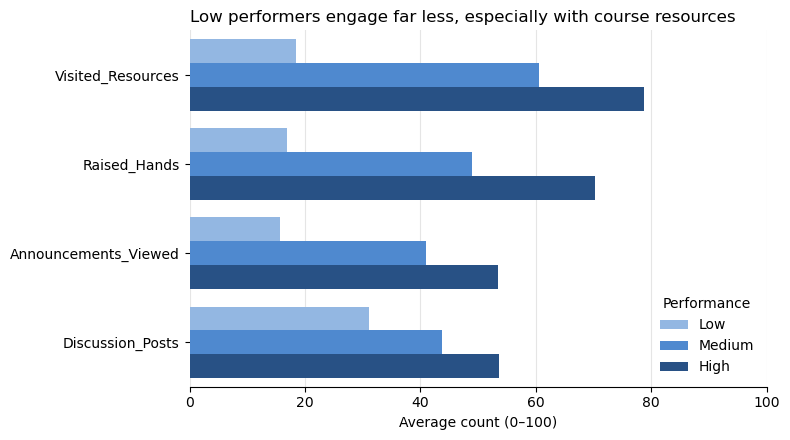

In [4]:
# Cell 3b: Grouped bar chart of average engagement by performance level
import matplotlib.pyplot as plt
import seaborn as sns

# Order behaviours by the High - Low gap (largest first)
behaviour_order = (
    engagement_by_perf.loc["High - Low gap", engagement_cols]
    .sort_values(ascending=False).index.tolist()
)

# Long format: one row per (performance, behaviour)
plot_df = (
    engagement_by_perf.loc[["Low", "Medium", "High"], engagement_cols]
    .reset_index()
    .melt(id_vars="Performance", var_name="Behaviour", value_name="Average")
)

# One blue from light to dark: darker = higher performance
perf_colors = {"Low": "#86b6ef", "Medium": "#3987e5", "High": "#184f95"}

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=plot_df, y="Behaviour", x="Average",
    hue="Performance", hue_order=["Low", "Medium", "High"],
    order=behaviour_order, palette=perf_colors, ax=ax,
)

ax.set_title("Low performers engage far less, especially with course resources", loc="left")
ax.set_xlabel("Average count (0–100)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
sns.despine(left=True)
ax.legend(title="Performance", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## 4. Topics: Low share by subject
Topics with fewer than 30 records are flagged, because their rates can change a lot with a few students.

In [5]:
# Cell 4: Low share by topic, sorted from highest to lowest
topic_summary = (
    df.groupby("Topic")
      .agg(records=("Record_ID", "count"),
           low_records=("Is_Low_Performer", "sum"),
           low_share=("Is_Low_Performer", "mean"))
      .sort_values("low_share", ascending=False)
)
topic_summary["low_share"] = (topic_summary["low_share"] * 100).round(1)
topic_summary["small_sample"] = topic_summary["records"] < 30
topic_summary

,records,low_records,low_share,small_sample
Topic,,,,
IT,95,38,40.0,False
Chemistry,24,8,33.3,True
Math,21,7,33.3,True
Spanish,25,8,32.0,True
Arabic,59,17,28.8,False
Quran,22,6,27.3,True
English,45,10,22.2,False
French,63,14,22.2,False
Science,51,10,19.6,False


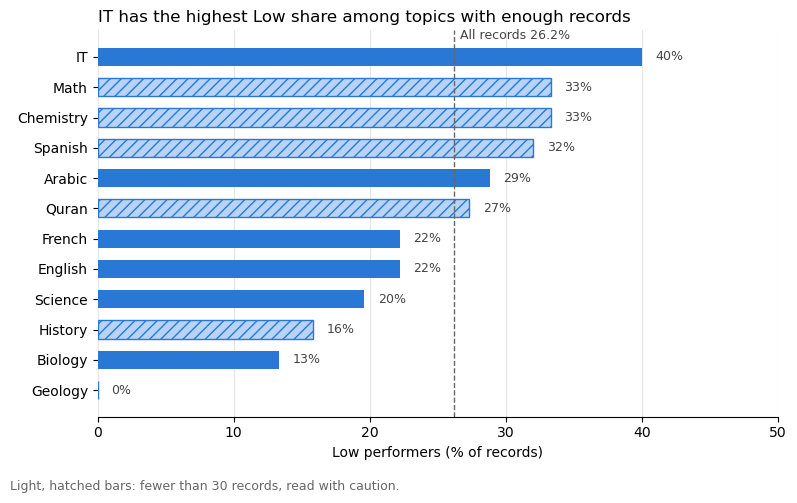

In [7]:
# Cell 4b: Low share by topic, with the overall baseline and small samples marked
baseline = low_share * 100   # 26.2 from Cell 1

plot_topics = topic_summary.sort_values("low_share")   # lowest at the bottom
colors = ["#b7d3f6" if small else "#2a78d6" for small in plot_topics["small_sample"]]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(plot_topics.index, plot_topics["low_share"], color=colors, height=0.6)

# Hatch the small-sample bars so the difference is not colour-only
for bar, small in zip(bars, plot_topics["small_sample"]):
    if small:
        bar.set_hatch("///")
        bar.set_edgecolor("#2a78d6")

# Value labels at the end of each bar
for bar, value in zip(bars, plot_topics["low_share"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{value:.0f}%", va="center", fontsize=9, color="#444444")

ax.axvline(baseline, color="#666666", linestyle="--", linewidth=1)
ax.text(baseline + 0.5, len(plot_topics) - 0.4, f"All records {baseline:.1f}%",
        fontsize=9, color="#444444")

ax.set_title("IT has the highest Low share among topics with enough records", loc="left")
ax.set_xlabel("Low performers (% of records)")
ax.set_xlim(0, 50)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
sns.despine(left=True)

fig.text(0.01, 0.01, "Light, hatched bars: fewer than 30 records, read with caution.",
         fontsize=9, color="#666666")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## Summary
- Attendance: records with 7+ absences had a 60.3% Low share, vs 3.8% for under 7.
- Engagement: Visited_Resources and Raised_Hands show the largest High–Low gaps; Discussion the smallest.
- Topics: IT has the highest Low share (40.0%) among topics with 30+ records.
These are associations, not causes.